#### Load the trained model and generate GPS trajectories

Generates the same way as `generate.py`: the trained NYC model, one trajectory per **test** condition
(`head_test.npy`, in order, so generated trajectory *i* matches real test trip *i*), rescaled with the statistics
of the **training** trips (`traj_stats.npy`), with the same sampling settings and seed. `traj.npy` (training
trajectories) is only used for a plot, and the loss plot reads the training loss.

In [ ]:
!pip install ipywidgets tqdm --upgrade

In [2]:
import sys
import os

# Adds the parent directory (DiffTraj root) to the system path
root_path = os.path.abspath(os.path.join('..'))
if root_path not in sys.path:
    sys.path.append(root_path)

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm.notebook import tqdm
from types import SimpleNamespace
from utils.Traj_UNet import *
from utils.config import args
from utils.utils import *
from torch.utils.data import DataLoader

In [ ]:
temp = {}
for k, v in args.items():
    temp[k] = SimpleNamespace(**v)

config = SimpleNamespace(**temp)

# Same model as generate.py: set the run folder, training timestamp and checkpoint
path = '../DiffTraj/NYC_moves_train_steps=500_len=256_0.05_bs=256/'   # repo/DiffTraj/<run>/
file = '10-14-15-11-04'                                               # training timestamp
checkpoint = 'unet_2000.pt'

unet = Guide_UNet(config).cuda()
# load the model
unet.load_state_dict(torch.load(path + 'models/' + file + '/' + checkpoint, map_location='cuda'))
unet.eval()   # as in generate.py: no dropout while generating


In [ ]:
n_steps = config.diffusion.num_diffusion_timesteps
beta = torch.linspace(config.diffusion.beta_start,
                          config.diffusion.beta_end, n_steps).cuda()
alpha = 1. - beta
alpha_bar = torch.cumprod(alpha, dim=0)

# sampling settings of generate.py
eta = 0.0
timesteps = 100
skip = n_steps // timesteps
seq = list(range(0, n_steps, skip))
seed = 101

# Conditions to generate from: the TEST trips (head_test.npy), like generate.py.
# shuffle=False keeps the order: synthetic[i] is generated from head_test.npy[i] (real test trip i).
# head.npy holds the TRAIN conditions the model was trained on.
batchsize = 500
head_file = '../head_test.npy'
head = np.load(head_file, allow_pickle=True)
head = torch.from_numpy(head).float()
dataloader = DataLoader(head, batch_size=batchsize, shuffle=False, num_workers=4)
print(f'{len(head)} conditions from {head_file}')


In [ ]:
# Rescaling statistics of the TRAIN trips (prepare_data.py -> traj_stats.npy), as in generate.py
stats = np.load('../traj_stats.npy', allow_pickle=True).item()
hmean    = np.asarray(stats['hmean'])
hstd     = np.asarray(stats['hstd'])
len_mean = float(stats['len_mean'])
len_std  = float(stats['len_std'])
mean     = np.asarray(stats['mean'])   # [lat_mean, lng_mean]
std      = np.asarray(stats['std'])    # [lat_std,  lng_std]
print(f'mean={mean.tolist()}  std={std.tolist()}  len_mean={len_mean:.2f}  len_std={len_std:.2f}')

# Not used any more (kept for reference):
# Chengdu values of the original notebook
# hmean=[0, 10283.41600429,   961.66920921,   292.30299616,    36.02766493, 10.98568072]
# hstd=[1, 8782.599246414231, 379.41939897358264, 107.24874828393955, 28.749924691281066, 8.774629812281198]
# mean = np.array([104.07596303,   30.68085491])
# std = np.array([2.15106194e-02, 1.89193207e-02])
# len_mean = 292.30299616  # Chengdu
# len_std = 107.2487482839  # Chengdu
# Values typed in for an earlier NYC run (they don't match the current data split)
# hmean=[0.0, 6929.1435546875, 12.266952514648438, 354.8415222167969, 19.64846420288086, 662.857177734375]
# hstd=[1.0, 5297.8466796875, 25.247751235961914, 177.12384033203125, 239.0599365234375, 496.4592590332031]
# len_mean=354.84152742073695
# len_std=177.1238435058475
# mean=[40.69339764242999, -74.04657522386194]
# std=[0.095722190514572, 0.08813045071354533]


In [ ]:
# Generate one trajectory per condition, in order (same steps as generate.py)
torch.manual_seed(seed)
np.random.seed(seed)

Gen_traj = []
Gen_head = []
seq_next = [-1] + seq[:-1]
for head in tqdm(dataloader):
    current_batchsize = len(head)
    lengths = (head[:, 3] * len_std + len_mean).int().clamp(min=2).numpy()
    Gen_head.extend(head[:, :6].numpy() * hstd + hmean)
    head = head.cuda()
    # Start with random noise, created on the GPU like in generate.py (same seed -> same noise)
    x = torch.randn(current_batchsize, 2, config.data.traj_length, device='cuda')
    for i, j in zip(reversed(seq), reversed(seq_next)):
        t = torch.full((current_batchsize,), i, device='cuda', dtype=torch.float)
        next_t = torch.full((current_batchsize,), j, device='cuda', dtype=torch.float)
        with torch.no_grad():
            pred_noise = unet(x, t, head)
            x = p_xt(x, pred_noise, t, next_t, beta, eta)
    trajs = x.cpu().numpy()[:, :2, :]
    # resample each trajectory to its length and rescale to latitude / longitude
    for k in range(current_batchsize):
        Gen_traj.append(resample_trajectory(trajs[k].T, int(lengths[k])) * std + mean)
print(f"Generated {len(Gen_traj)} trajectories")


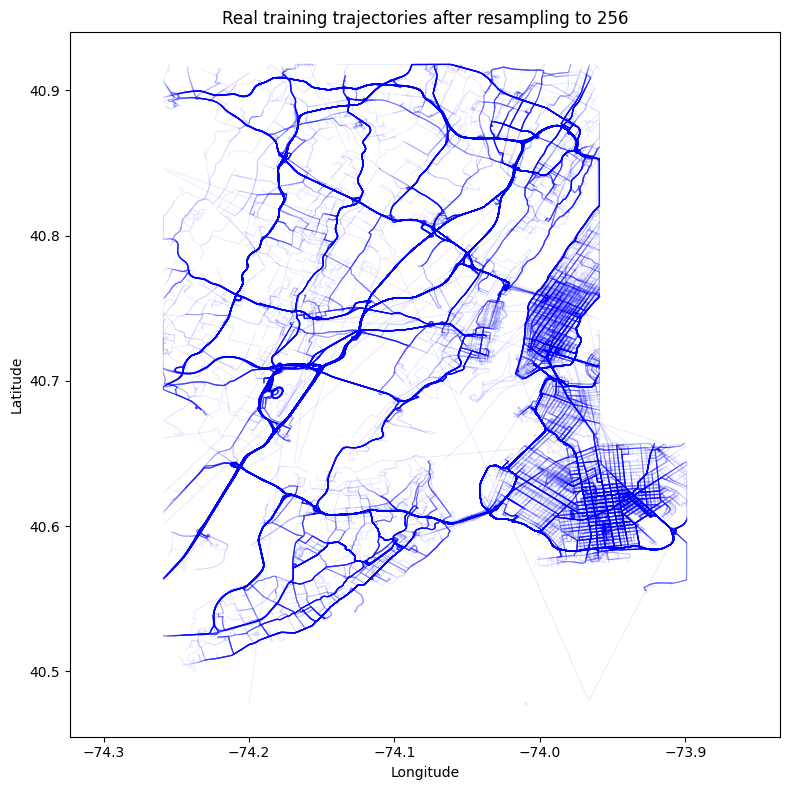

In [8]:
# Plot actual trajectories that DiffTraj sees during training

traj_train = np.load("../traj.npy", allow_pickle=True)

plt.figure(figsize=(8, 8))

for i in range(len(traj_train)):
    traj = traj_train[i]          # shape [2, 256]
    traj = traj.T                 # shape [256, 2]
    traj = traj * std + mean

    plt.plot(
        traj[:, 1],
        traj[:, 0],
        color="blue",
        alpha=0.08,
        linewidth=0.8
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Real training trajectories after resampling to 256")
plt.axis("equal")
plt.tight_layout()
plt.show()

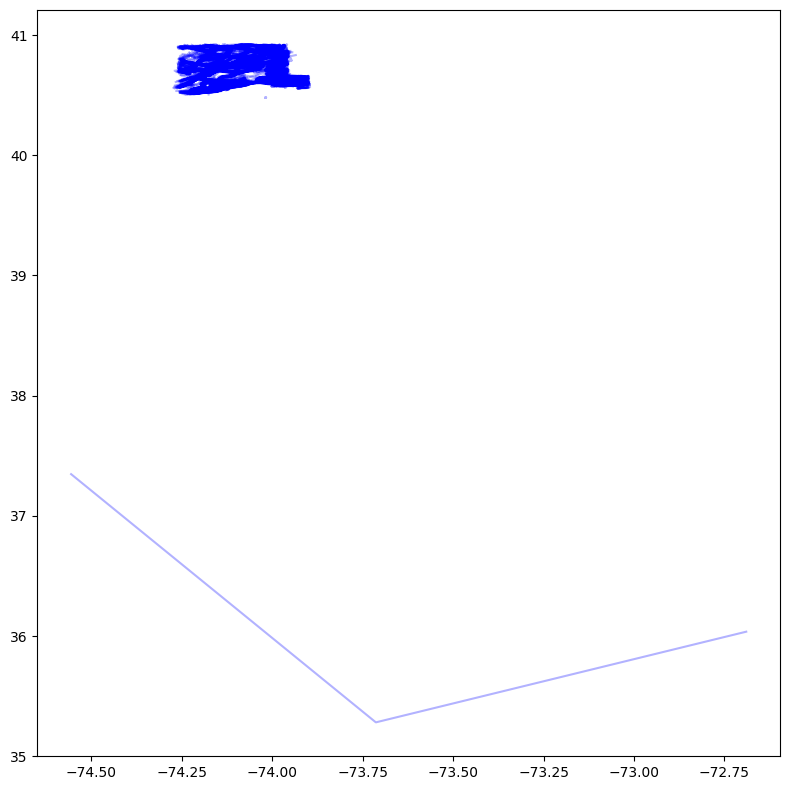

In [9]:
plt.figure(figsize=(8,8))
for i in range(len(Gen_traj)):
    traj=Gen_traj[i]
    plt.plot(traj[:,1],traj[:,0],color='blue',alpha=0.3)
plt.tight_layout()
plt.savefig('new_york.png')
plt.show()

In [10]:
lat_min, lat_max = 40.45, 40.95
lon_min, lon_max = -74.30, -73.85

bad = []

for i, traj in enumerate(Gen_traj):
    lat = traj[:, 0]
    lon = traj[:, 1]

    in_bounds = (
        (lat >= lat_min) & (lat <= lat_max) &
        (lon >= lon_min) & (lon <= lon_max)
    )

    if not np.all(in_bounds):
        bad.append((i, np.where(~in_bounds)[0], traj[~in_bounds]))

print("Number of bad trajectories:", len(bad))
print("First bad trajectory:", bad[0] if bad else None)

Number of bad trajectories: 1
First bad trajectory: (3946, array([0, 1, 2]), array([[ 37.34708871, -74.55594908],
       [ 35.28189661, -73.71360867],
       [ 36.036311  , -72.68982093]]))


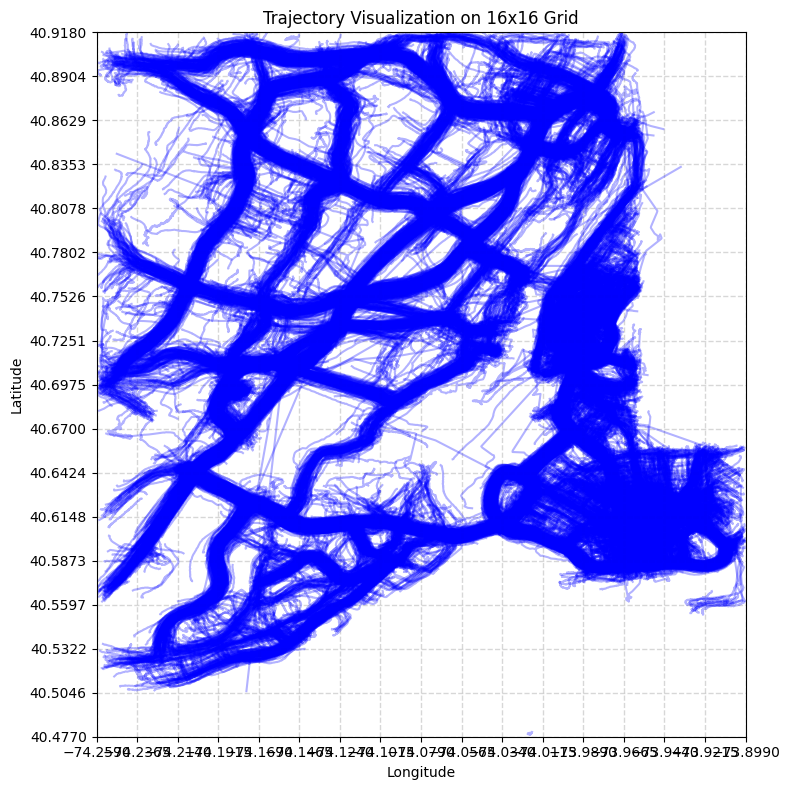

In [11]:
lat_min = 40.4770392
lat_max = 40.9179995
lon_min = -74.2589998
lon_max = -73.8990007
grid_size = 16

plt.figure(figsize=(8, 8))

for traj in Gen_traj:
    lat = traj[:, 0]
    lon = traj[:, 1]

    in_bounds = (
        (lat >= lat_min) & (lat <= lat_max) &
        (lon >= lon_min) & (lon <= lon_max)
    )

    if np.all(in_bounds):
        plt.plot(lon, lat, color="blue", alpha=0.3)

plt.xlim(lon_min, lon_max)
plt.ylim(lat_min, lat_max)

# Add 16x16 grid
plt.xticks(np.linspace(lon_min, lon_max, grid_size + 1))
plt.yticks(np.linspace(lat_min, lat_max, grid_size + 1))
plt.grid(True, linestyle="--", linewidth=1, alpha=0.5)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Trajectory Visualization on 16x16 Grid")

plt.tight_layout()
plt.savefig("new_york.png", dpi=300)
plt.show()

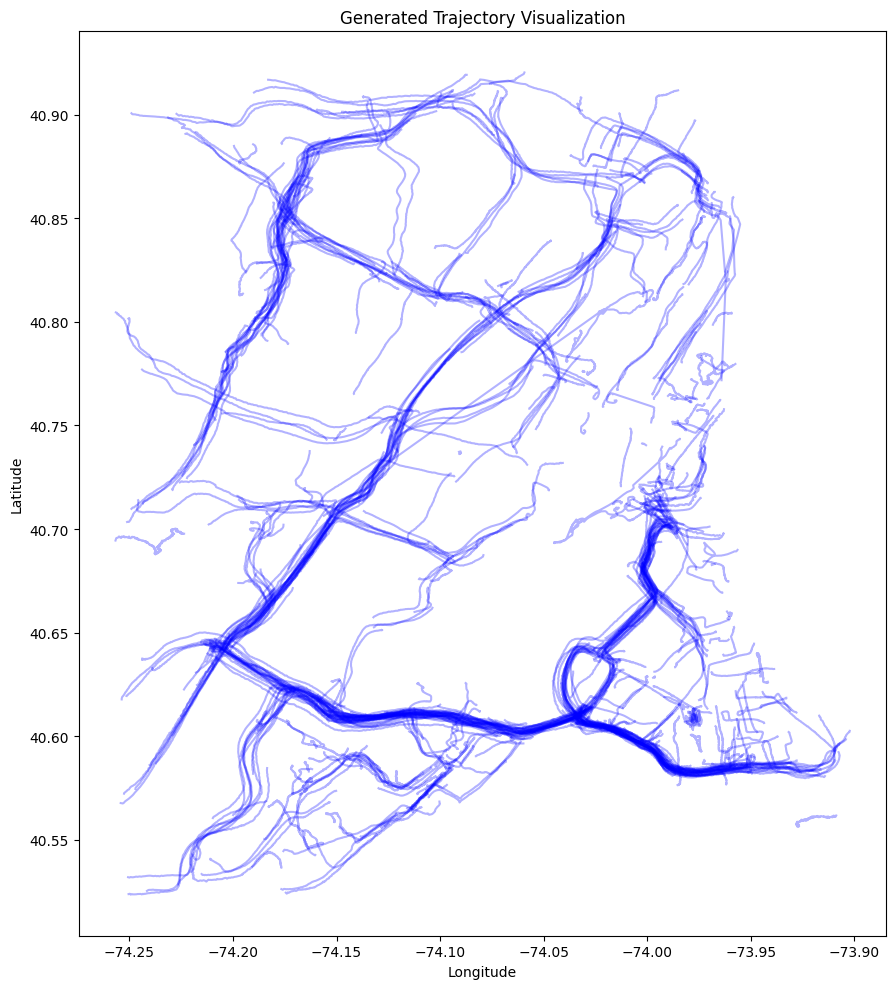

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

for i in range(0, 500):
    traj = Gen_traj[i]
    ax.plot(traj[:, 1], traj[:, 0], alpha=0.3, color='blue')

ax.set_title("Generated Trajectory Visualization")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

# Match real trajectory graph shape/scale
ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.savefig("new_york_no_grid.png", dpi=300)
plt.show()

In [ ]:
# Save like generate.py: object array of (L, 2) [lat, lng], the row of head_test.npy used for each
# trajectory, and the settings. Saved in a notebook/ subfolder, so generate.py's output for the same run
# (Files/<timestamp>/) is not overwritten and the two can be compared.
import json
out_dir = path + 'Files/' + file + '/notebook/'
os.makedirs(out_dir, exist_ok=True)
gen_data = np.empty(len(Gen_traj), dtype=object)
for k, tr in enumerate(Gen_traj):
    gen_data[k] = tr
np.save(out_dir + 'synthetic_trajectories.npy', gen_data, allow_pickle=True)
np.save(out_dir + 'synthetic_index.npy', np.arange(len(Gen_traj)))   # synthetic[i] <- head_test.npy[i]
with open(out_dir + 'generation_info.json', 'w') as f:
    json.dump({'model': path + 'models/' + file + '/' + checkpoint, 'head': head_file,
               'stats': '../traj_stats.npy', 'n': len(Gen_traj), 'timesteps': timesteps, 'eta': eta,
               'seed': seed, 'batch_size': batchsize}, f, indent=2)
print('saved to', out_dir)

# Compare with generate.py's output for the same run, if there is one
ref_path = path + 'Files/' + file + '/synthetic_trajectories.npy'
if os.path.exists(ref_path):
    ref = np.load(ref_path, allow_pickle=True)
    same_shape = len(ref) == len(gen_data) and all(len(a) == len(b) for a, b in zip(ref, gen_data))
    print('same number of trajectories and points as generate.py:', same_shape)
    if same_shape:
        diff = max(np.abs(np.asarray(a) - np.asarray(b)).max() for a, b in zip(ref, gen_data))
        print(f'largest coordinate difference: {diff:.2e} degrees (GPU arithmetic can cause tiny differences)')
else:
    print('no generate.py output for this run yet:', ref_path)


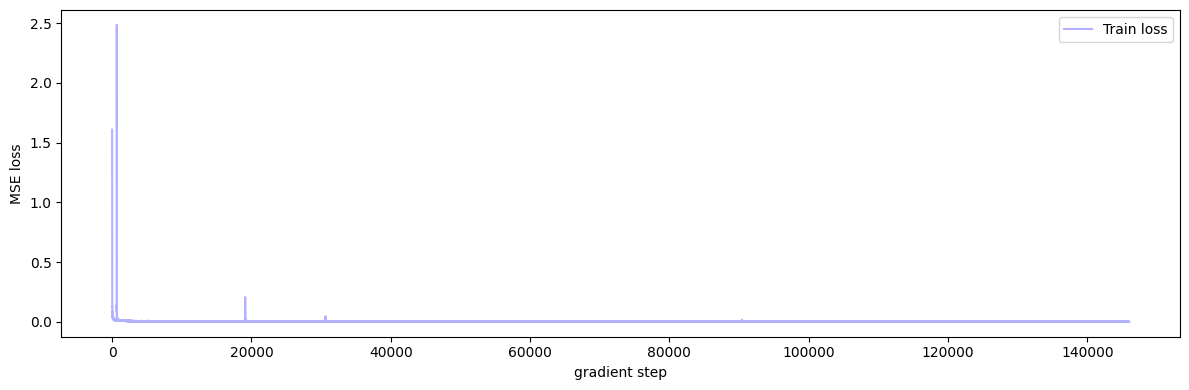

Starting loss: 0.1213
Final loss:    0.0012


In [14]:
import re
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Training loss: main.py saves every loss so far to results/loss_<epoch>.npy every 50 epochs,
# so the file with the highest epoch has the whole run. The results/ folder is made by training
# (on the HPC: repo/DiffTraj/<run>/results/); copy it next to models/ and Files/ to plot it here.
loss_files = sorted(Path(path, 'results').glob('loss_*.npy'),
                    key=lambda p: int(re.findall(r'\d+', p.stem)[0]))
if not loss_files:
    print(f"No loss file in {Path(path, 'results')}: copy results/loss_2000.npy from the training run.")
else:
    loss_path = loss_files[-1]
    losses = np.load(loss_path)
    print('Loss file:', loss_path.name)

    plt.figure(figsize=(12, 4))
    plt.plot(losses, alpha=0.3, color='blue', label='Train loss')
    plt.xlabel('gradient step')
    plt.ylabel('MSE loss')
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"Starting loss: {losses[:100].mean():.4f}")
    print(f"Final loss:    {losses[-100:].mean():.4f}")
